Heart Disease Prediction: Analyzing and Addressing Overfitting

Introduction: This project aims to build a machine learning model to predict the presence of heart disease using the Random Forest Classifier.

The main objective is not only to build a predictive model, but also to investigate the problem of overfitting and understand how hyperparameter tuning can help improve the model's generalization performance.

Through multiple experiments, we will compare model performance before and after adjusting the hyperparameters.

1. Importing Libraries
In this section, we import the required Python libraries for data manipulation, visualization, model building, and evaluation.

In [1]:
# Data visualization
%matplotlib inline
import matplotlib.pyplot as plt

# Data manipulation
import pandas as pd
import numpy as np

# Data splitting
from sklearn.model_selection import train_test_split

# Machine Learning Model
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import classification_report

2. Loading the Dataset
The Heart Disease dataset is used in this project to train and evaluate the machine learning model to predict whether a person has heart disease.

In [2]:
heart_disease = pd.read_csv("Data/heart-disease.csv")

# Display the first five rows
heart_disease.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


3. Exploratory Data Analysis (EDA)
Before building the model, we explore the dataset to understand its structure, feature distributions, and target variable.

This step helps us identify patterns and understand the data we are working with.

In [3]:
# Statistical summary of the dataset
heart_disease.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000
mean,54.366337,0.683168,0.966997,131.623762,246.264026,0.148515,0.528053,149.646865,0.326733,1.039604,1.399340,0.729373,2.313531,0.544554
std,9.082101,0.466011,1.032052,17.538143,51.830751,0.356198,0.525860,22.905161,0.469794,1.161075,0.616226,1.022606,0.612277,0.498835
min,29.000000,0.000000,0.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,47.500000,0.000000,0.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,55.000000,1.000000,1.000000,130.000000,240.000000,0.000000,1.000000,153.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,274.500000,0.000000,1.000000,166.000000,1.000000,1.600000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


In [4]:
# Check the distribution of the target variable
heart_disease['target'].value_counts()

target
1    165
0    138
Name: count, dtype: int64

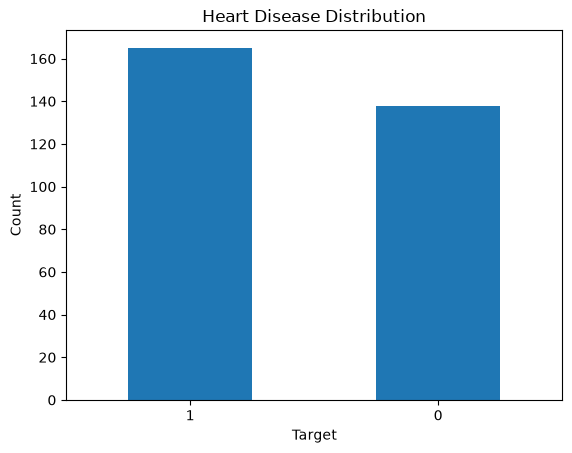

In [5]:
heart_disease['target'].value_counts().plot(
    kind='bar',
    title='Heart Disease Distribution'
)

plt.xlabel('Target')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.show()

4. Data Preparation
In this section, we separate the input features (X) from the target variable (y).

The dataset is then divided into training and testing sets to evaluate the model's ability to generalize to unseen data.

In [6]:
# Features
X = heart_disease.drop(['target'], axis=1)

# Target
y = heart_disease['target']

In [7]:
# Use train_test_split to split X & y into training and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

5. Experiment 1: Baseline Random Forest Model
In the first experiment, we train a Random Forest Classifier using its default hyperparameters.

This model serves as a baseline to evaluate the initial performance and identify whether overfitting occurs.

In [8]:

# Initialize the baseline model
baseline_model = RandomForestClassifier(random_state=42)

# Train the model
baseline_model.fit(X_train, y_train)

# Make predictions
baseline_preds = baseline_model.predict(X_test)

In [9]:
# Evaluate training and testing accuracy
baseline_train_score = baseline_model.score(X_train, y_train)
baseline_test_score = baseline_model.score(X_test, y_test)

print("Training Accuracy:", baseline_train_score)
print("Testing Accuracy:", baseline_test_score)

print(
    "Accuracy Gap:",
    baseline_train_score - baseline_test_score
)

Training Accuracy: 1.0
Testing Accuracy: 0.8360655737704918
Accuracy Gap: 0.16393442622950816


In [10]:
print(classification_report(y_test, baseline_preds))

              precision    recall  f1-score   support

           0       0.95      0.68      0.79        28
           1       0.78      0.97      0.86        33

    accuracy                           0.84        61
   macro avg       0.87      0.82      0.83        61
weighted avg       0.86      0.84      0.83        61



6. Experiment 2: Reducing Overfitting Through Hyperparameter Tuning
After evaluating the baseline model, we investigate whether adjusting the Random Forest hyperparameters can reduce overfitting.

We introduce constraints on tree complexity by limiting the maximum depth and increasing the minimum number of samples required for splitting and leaf nodes.

In [11]:

# Initialize the tuned model
tuned_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=4,
    min_samples_split=10,
    min_samples_leaf=4,
    max_features='sqrt',
    random_state=42
)

# Train the model
tuned_model.fit(X_train, y_train)

# Make predictions
tuned_preds = tuned_model.predict(X_test)

In [12]:
# Training Accuracy
tuned_train_score = tuned_model.score(X_train, y_train)

# Testing Accuracy
tuned_test_score = tuned_model.score(X_test, y_test)

print("Training Accuracy:", tuned_train_score)
print("Testing Accuracy:", tuned_test_score)

print(
    "Accuracy Gap:",
    tuned_train_score - tuned_test_score
)

Training Accuracy: 0.9049586776859504
Testing Accuracy: 0.8032786885245902
Accuracy Gap: 0.10167998916136023


In [13]:
print(classification_report(y_test, tuned_preds))

              precision    recall  f1-score   support

           0       0.94      0.61      0.74        28
           1       0.74      0.97      0.84        33

    accuracy                           0.80        61
   macro avg       0.84      0.79      0.79        61
weighted avg       0.84      0.80      0.79        61



In [14]:
# View the different shapes of the training and test datasets
###
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((242, 13), (61, 13), (242,), (61,))

7. Model Performance Comparison
In this section, we compare the baseline and tuned Random Forest models to evaluate the impact of hyperparameter tuning on overfitting and generalization performance.

In [15]:
results = pd.DataFrame({
    'Model': ['Baseline', 'Tuned'],
    'Training Accuracy': [
        baseline_train_score,
        tuned_train_score
    ],
    'Testing Accuracy': [
        baseline_test_score,
        tuned_test_score
    ],
    'Accuracy Gap': [
        baseline_train_score - baseline_test_score,
        tuned_train_score - tuned_test_score
    ]
})

results

,Model,Training Accuracy,Testing Accuracy,Accuracy Gap
0,Baseline,1.000000,0.836066,0.163934
1,Tuned,0.904959,0.803279,0.101680


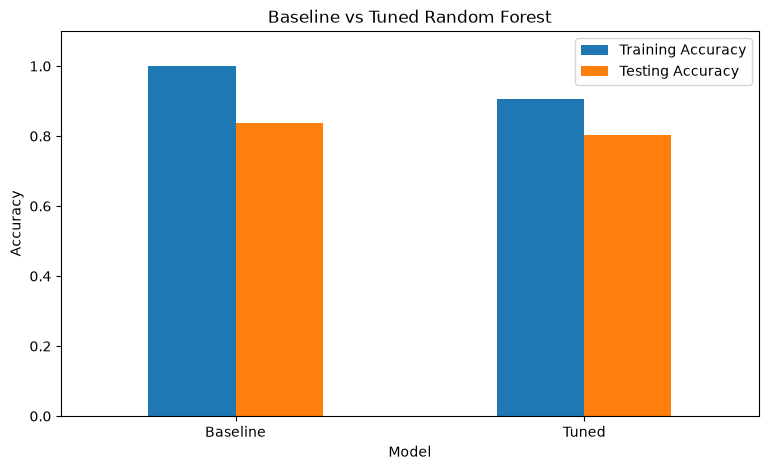

In [16]:
results.set_index('Model')[
    ['Training Accuracy', 'Testing Accuracy']
].plot(
    kind='bar',
    figsize=(9, 5)
)

plt.title('Baseline vs Tuned Random Forest')
plt.ylabel('Accuracy')
plt.xlabel('Model')
plt.xticks(rotation=0)
plt.ylim(0, 1.1)
plt.show()

8. Conclusion
In this project, I built a Random Forest model to predict heart disease and explored the concept of overfitting.

I trained a baseline model and then adjusted its hyperparameters to see how these changes affect training and testing accuracy.

The baseline model achieved 100% training accuracy and 83.6% testing accuracy, indicating overfitting.

After adjusting the hyperparameters, the training accuracy decreased to 90.5%, and the accuracy gap was reduced from 16.4% to 10.2%.

However, the testing accuracy also decreased slightly to 80.3%.